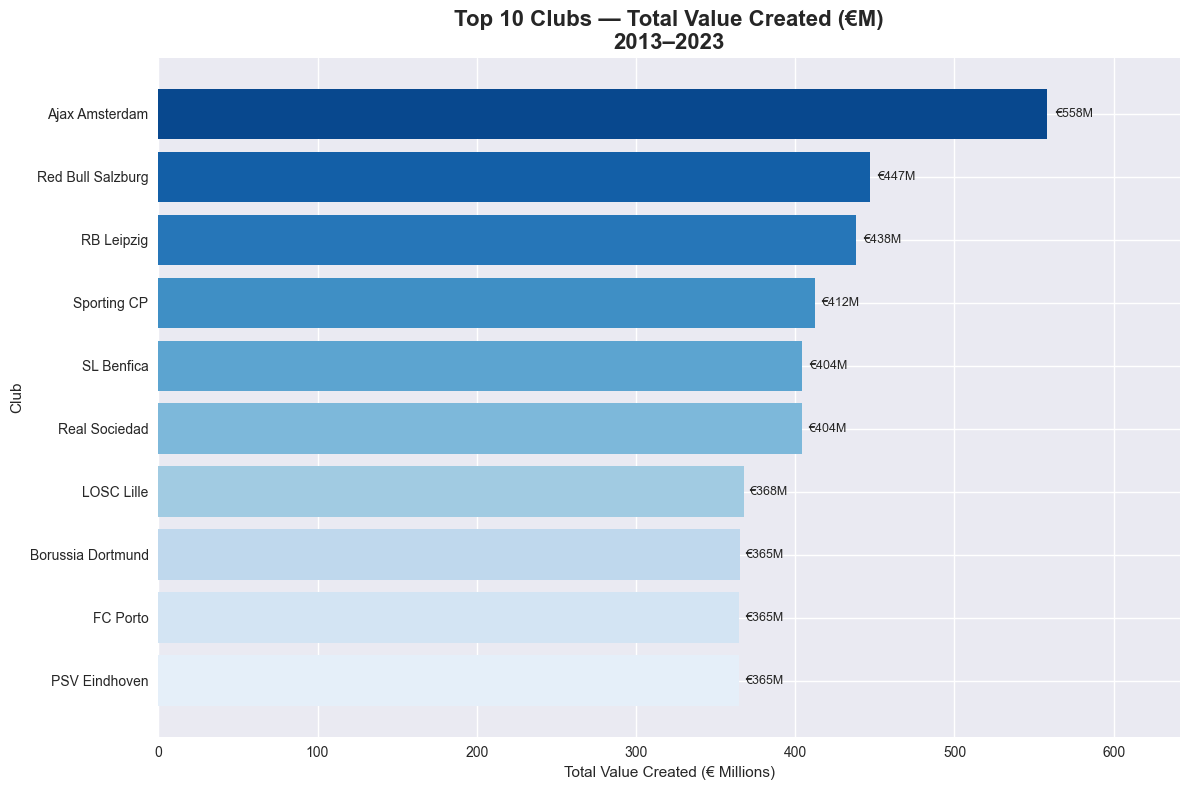

In [5]:
# ==============================
# 1. Libraries
# ==============================
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")

# ==============================
# 2. Load Data
# ==============================
df = pd.read_csv("player_valuations.csv")
players_df = pd.read_csv("players.csv")

# ==============================
# 3. Merge (add player name)
# ==============================
players_df = players_df[['player_id', 'name']].copy()

df['player_id'] = df['player_id'].astype(str).str.strip()
players_df['player_id'] = players_df['player_id'].astype(str).str.strip()

df = df.merge(players_df, on='player_id', how='left')

# ==============================
# 4. Data Preparation
# ==============================
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['market_value_in_eur'] = pd.to_numeric(df['market_value_in_eur'], errors='coerce')

# Remove dados inválidos
df = df.dropna(subset=['date', 'market_value_in_eur'])

# ==============================
# 5. Time Filter (2013–2023)
# ==============================
df = df[(df['date'].dt.year >= 2013) & (df['date'].dt.year <= 2023)]

# ==============================
# 6. Sorting
# ==============================
df = df.sort_values(['player_id', 'date'])

# ==============================
# 7. Identify Club Periods
# ==============================
df['club_change'] = (
    df['current_club_id'] != df.groupby('player_id')['current_club_id'].shift(1)
)

df['club_period'] = df.groupby('player_id')['club_change'].cumsum()

# ==============================
# 8. Aggregate per Club Period
# ==============================
club_periods = (
    df.groupby([
        'player_id',
        'name',
        'current_club_id',
        'current_club_name',
        'club_period'
    ])
    .agg(
        start_date=('date', 'first'),
        end_date=('date', 'last'),
        initial_value=('market_value_in_eur', 'first'),
        final_value=('market_value_in_eur', 'last')
    )
    .reset_index()
)

# ==============================
# 9. Growth Calculation
# ==============================
# Evita divisão inválida
club_periods = club_periods[club_periods['initial_value'] > 0]

club_periods['value_growth'] = (
    club_periods['final_value'] - club_periods['initial_value']
)

club_periods['growth_pct'] = (
    club_periods['final_value'] / club_periods['initial_value'] - 1
)

# ==============================
# 10. Time & Value Filters
# ==============================
club_periods['duration_days'] = (
    club_periods['end_date'] - club_periods['start_date']
).dt.days

club_periods = club_periods[
    (club_periods['duration_days'] > 90) &
    (club_periods['initial_value'] > 100000)
]

# ==============================
# 11. Club-Level Analysis
# ==============================
club_analysis = (
    club_periods
    .groupby(['current_club_id', 'current_club_name'])
    .agg(
        total_value_created=('value_growth', 'sum'),
        avg_value_created=('value_growth', 'mean'),
        median_value_created=('value_growth', 'median'),
        avg_growth_pct=('growth_pct', 'mean'),
        players=('player_id', 'nunique'),
        positive_growth=('value_growth', lambda x: (x > 0).sum()),
        negative_growth=('value_growth', lambda x: (x < 0).sum())
    )
    .reset_index()
)

# ==============================
# 12. Efficiency Metrics (Revised)
# ==============================
club_analysis['value_per_player'] = (
    club_analysis['total_value_created'] / club_analysis['players']
)

# Total de casos válidos (exclui crescimento zero)
club_analysis['total_cases'] = (
    club_analysis['positive_growth'] + club_analysis['negative_growth']
)

club_analysis['positive_rate'] = np.where(
    club_analysis['total_cases'] > 0,
    club_analysis['positive_growth'] / club_analysis['total_cases'],
    np.nan
)

# ==============================
# 13. Robustness Filter
# ==============================
club_analysis = club_analysis[club_analysis['players'] >= 5]

# ==============================
# 14. Ranking
# ==============================
top_clubs = club_analysis.sort_values(
    'total_value_created', ascending=False
).head(10)

# ==============================
# 15. Visualization
# ==============================
plt.figure(figsize=(12, 8))
 
plt.barh(
    top_clubs['current_club_name'],
    top_clubs['total_value_created'] / 1e6,
    color=sns.color_palette("Blues_r", len(top_clubs))
)
 
plt.title('Top 10 Clubs — Total Value Created (€M)\n2013–2023',
          fontsize=16, fontweight='bold')
plt.xlabel('Total Value Created (€ Millions)')
plt.ylabel('Club')
plt.gca().invert_yaxis()
 
for i, value in enumerate(top_clubs['total_value_created'] / 1e6):
    plt.text(value * 1.01, i, f'€{value:.0f}M', va='center', fontsize=9)
 
plt.margins(x=0.15)
plt.tight_layout()
plt.savefig("club_value_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# ==============================
# PRINTS PARA ANÁLISE
# ==============================

print("=" * 70)
print("ANÁLISE DE VALOR CRIADO POR CLUBES (2013-2023)")
print("=" * 70)

print(f"\nTotal de registros processados: {len(df)}")
print(f"Total de clubes analisados: {len(club_analysis)}")
print(f"Clubes com 5+ jogadores: {len(club_analysis[club_analysis['players'] >= 5])}")

print("\n" + "=" * 70)
print("ESTATÍSTICAS GERAIS")
print("=" * 70)
print(club_analysis[['total_value_created', 'avg_value_created', 'avg_growth_pct', 'positive_rate', 'players']].describe())

print("\n" + "=" * 70)
print("TOP 10 CLUBES - VALOR TOTAL CRIADO")
print("=" * 70)
print(top_clubs[['current_club_name', 'total_value_created', 'players', 'positive_growth', 'negative_growth', 'positive_rate', 'avg_growth_pct']].to_string())

print("\n" + "=" * 70)
print("CORRELAÇÃO: NÚMERO DE JOGADORES vs VALOR CRIADO")
print("=" * 70)
from scipy import stats
corr_players_value = club_analysis['players'].corr(club_analysis['total_value_created'])
r_players_value, p_value_players = stats.pearsonr(club_analysis['players'], club_analysis['total_value_created'])
print(f"Correlação: {corr_players_value:.4f}")
print(f"P-value: {p_value_players:.6f}")

print("\n" + "=" * 70)
print("CORRELAÇÃO: TAXA DE SUCESSO (positive_rate) vs VALOR CRIADO")
print("=" * 70)
# Remove NaN para essa correlação
club_analysis_clean = club_analysis.dropna(subset=['positive_rate'])
corr_rate_value = club_analysis_clean['positive_rate'].corr(club_analysis_clean['total_value_created'])
r_rate_value, p_value_rate = stats.pearsonr(club_analysis_clean['positive_rate'], club_analysis_clean['total_value_created'])
print(f"Correlação: {corr_rate_value:.4f}")
print(f"P-value: {p_value_rate:.6f}")

print("\n" + "=" * 70)
print("CLUBES COM MAIOR EFICIÊNCIA (avg_growth_pct)")
print("=" * 70)
efficient_clubs = club_analysis.nlargest(10, 'avg_growth_pct')[['current_club_name', 'avg_growth_pct', 'players', 'total_value_created', 'positive_rate']]
print(efficient_clubs.to_string())

print("\n" + "=" * 70)
print("CLUBES COM PIOR EFICIÊNCIA (avg_growth_pct)")
print("=" * 70)
inefficient_clubs = club_analysis.nsmallest(10, 'avg_growth_pct')[['current_club_name', 'avg_growth_pct', 'players', 'total_value_created', 'positive_rate']]
print(inefficient_clubs.to_string())

ANÁLISE DE VALOR CRIADO POR CLUBES (2013-2023)

Total de registros processados: 394199
Total de clubes analisados: 1061
Clubes com 5+ jogadores: 1061

ESTATÍSTICAS GERAIS
       total_value_created  avg_value_created  avg_growth_pct  positive_rate  \
count         1.061000e+03       1.061000e+03     1061.000000    1061.000000   
mean          1.750596e+07       4.067805e+05        0.903650       0.551923   
std           6.055711e+07       1.000438e+06        1.484180       0.255877   
min          -3.971000e+08      -5.091026e+06       -0.740833       0.000000   
25%          -1.000000e+05      -1.071429e+04        0.084921       0.375000   
50%           1.250000e+06       1.089744e+05        0.420927       0.538462   
75%           1.030000e+07       4.464286e+05        1.130233       0.750000   
max           5.579250e+08       6.536940e+06       12.774987       1.000000   

           players  
count  1061.000000  
mean     27.438266  
std      27.094962  
min       5.000000  
25%

In [7]:
# ==============================
# INFORMAÇÕES ADICIONAIS NECESSÁRIAS
# ==============================

print("\n" + "=" * 70)
print("TOP 10 CLUBES - RANKING COMPLETO")
print("=" * 70)
top_10 = club_analysis.nlargest(10, 'total_value_created')
print(top_10[['current_club_name', 'total_value_created', 'avg_value_created', 'avg_growth_pct', 'players', 'positive_rate']].to_string(index=False))

print("\n" + "=" * 70)
print("BOTTOM 10 CLUBES - RANKING COMPLETO")
print("=" * 70)
bottom_10 = club_analysis.nsmallest(10, 'total_value_created')
print(bottom_10[['current_club_name', 'total_value_created', 'avg_value_created', 'avg_growth_pct', 'players', 'positive_rate']].to_string(index=False))

print("\n" + "=" * 70)
print("MEDIANA vs MÉDIA")
print("=" * 70)
print(f"Média de Valor Criado: €{club_analysis['total_value_created'].mean():,.0f}")
print(f"Mediana de Valor Criado: €{club_analysis['total_value_created'].median():,.0f}")
print(f"Média de Taxa de Sucesso: {club_analysis['positive_rate'].mean():.2%}")
print(f"Mediana de Taxa de Sucesso: {club_analysis['positive_rate'].median():.2%}")

print("\n" + "=" * 70)
print("DISTRIBUIÇÃO DE CLUBES")
print("=" * 70)
print(f"Clubes com valor criado POSITIVO: {(club_analysis['total_value_created'] > 0).sum()}")
print(f"Clubes com valor criado NEGATIVO: {(club_analysis['total_value_created'] < 0).sum()}")
print(f"Taxa de clubes bem-sucedidos: {(club_analysis['total_value_created'] > 0).sum() / len(club_analysis):.2%}")


TOP 10 CLUBES - RANKING COMPLETO
current_club_name  total_value_created  avg_value_created  avg_growth_pct  players  positive_rate
   Ajax Amsterdam            557925000       6.268820e+06        6.343754       86       0.575000
Red Bull Salzburg            446825000       6.383214e+06        5.036970       62       0.857143
       RB Leipzig            437975000       6.536940e+06        2.202155       65       0.593220
      Sporting CP            412200000       4.249485e+06        2.326446       91       0.573171
       SL Benfica            404500000       4.445055e+06        1.910525       87       0.488095
    Real Sociedad            404300000       5.390667e+06        2.513936       68       0.562500
       LOSC Lille            367550000       4.224713e+06        4.291136       82       0.605263
Borussia Dortmund            365000000       4.147727e+06        2.106601       83       0.500000
         FC Porto            364850000       4.146023e+06        1.020368       78  